# Module 1 — 기존 정제 데이터 기반 실행 결과

- 원본 읽기 금지 조건에 따라 `data/processed/pre_impute_data.csv`부터 실행함
- 입력 형식 정제·중복 제거·이상값의 결측 변환은 이미 완료된 입력임 — 해당 단계를 이번에 재실행한 결과가 아님
- 기존 분할과 입력 해시를 확인하고 날짜 보간·EDA·수치형 대치·특성 공학·검증·특징 비교를 실행함
- 결과는 `module1_preprocessing/reports/processed_replay/`에 별도 저장함
- 원본부터 실행하는 제출용 전체 파이프라인은 `01_eda_and_validation.ipynb`에 유지함


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / 'module1_preprocessing').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'module1_preprocessing').is_dir():
    raise RuntimeError('프로젝트 루트 또는 notebooks 폴더에서 실행 필요함')
sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
import pandas as pd
from pathlib import Path

from module1_preprocessing.preprocessing import load_raw, clean_schema, resolve_duplicate_batches
from module1_preprocessing.imputation import replace_outliers_with_nan, impute_missing_from_reference, interpolate_analysis_date
from module1_preprocessing.transformation import validate_targets, validate_model_features
from module1_preprocessing.features import engineer_features
from module1_preprocessing.splitting import stratified_train_val_test_split
from module1_preprocessing.validation import (
    check_ranges,
    format_range_violations,
    check_composition_sum,
    check_missing,
    plot_missing_before_after,
    plot_distributions,
    plot_correlation_heatmap,
    plot_ablation_results,
    plot_grade_distribution,
)
from module1_preprocessing.config import (
    COMPOSITION_COLUMNS, PROCESS_COLUMNS, TARGET_COLUMNS, NORMAL_RANGES, REFERENCE_EXCEPTION_RANGES,
    DERIVED_FEATURES, BASE_FEATURES,
)

FIGURES_DIR = ROOT / 'module1_preprocessing/reports/processed_replay/figures'

In [2]:
from module2_prediction.data_loading import load_modeling_inputs

pre_impute_df, stored_selection = load_modeling_inputs(ROOT / 'data/processed/pre_impute_data.csv')
outlier_flagged_df = pre_impute_df.copy()
interpolated_df = interpolate_analysis_date(outlier_flagged_df)
train_i = interpolated_df.index[interpolated_df['split'].eq('train')]
val_i = interpolated_df.index[interpolated_df['split'].eq('validation')]
test_i = interpolated_df.index[interpolated_df['split'].eq('test')]
print('기존 정제 데이터·분할 해시 확인 완료함')
print(f'Train {len(train_i)}행 / Validation {len(val_i)}행 / Test {len(test_i)}행')
print('분석일자 보간 후 결측:', interpolated_df['분석일자'].isna().sum())


기존 정제 데이터·분할 해시 확인 완료함
Train 294행 / Validation 63행 / Test 63행
분석일자 보간 후 결측: 0


## 3. 기존 데이터 분할 확인 및 초기 EDA

- 저장된 고정 분할을 그대로 사용하며 이번 실행에서 다시 분할하지 않음

In [3]:
# 분할 전후 원료등급 구성비 비교함
overall_ratio = (interpolated_df['원료등급'].value_counts(normalize=True) * 100).sort_index()
split_ratios = pd.DataFrame({
    '전체': overall_ratio,
    'Train': (interpolated_df.loc[train_i, '원료등급'].value_counts(normalize=True) * 100).sort_index(),
    'Validation': (interpolated_df.loc[val_i, '원료등급'].value_counts(normalize=True) * 100).sort_index(),
    'Test': (interpolated_df.loc[test_i, '원료등급'].value_counts(normalize=True) * 100).sort_index(),
})
split_ratios.round(1)

,전체,Train,Validation,Test
원료등급,,,,
A,35.2,35.4,34.9,34.9
B,38.6,38.8,38.1,38.1
C,26.2,25.9,27.0,27.0


### 3.1 배치ID 기준 인접 배치의 회수율 관계

- 배치ID가 처리 순서를 근사한다고 가정하고, 개발 데이터에서 순번 차이가 1인 쌍의 회수율 관계를 확인함
- 산점도에 Pearson 상관계수와 유효 쌍 수를 표시함

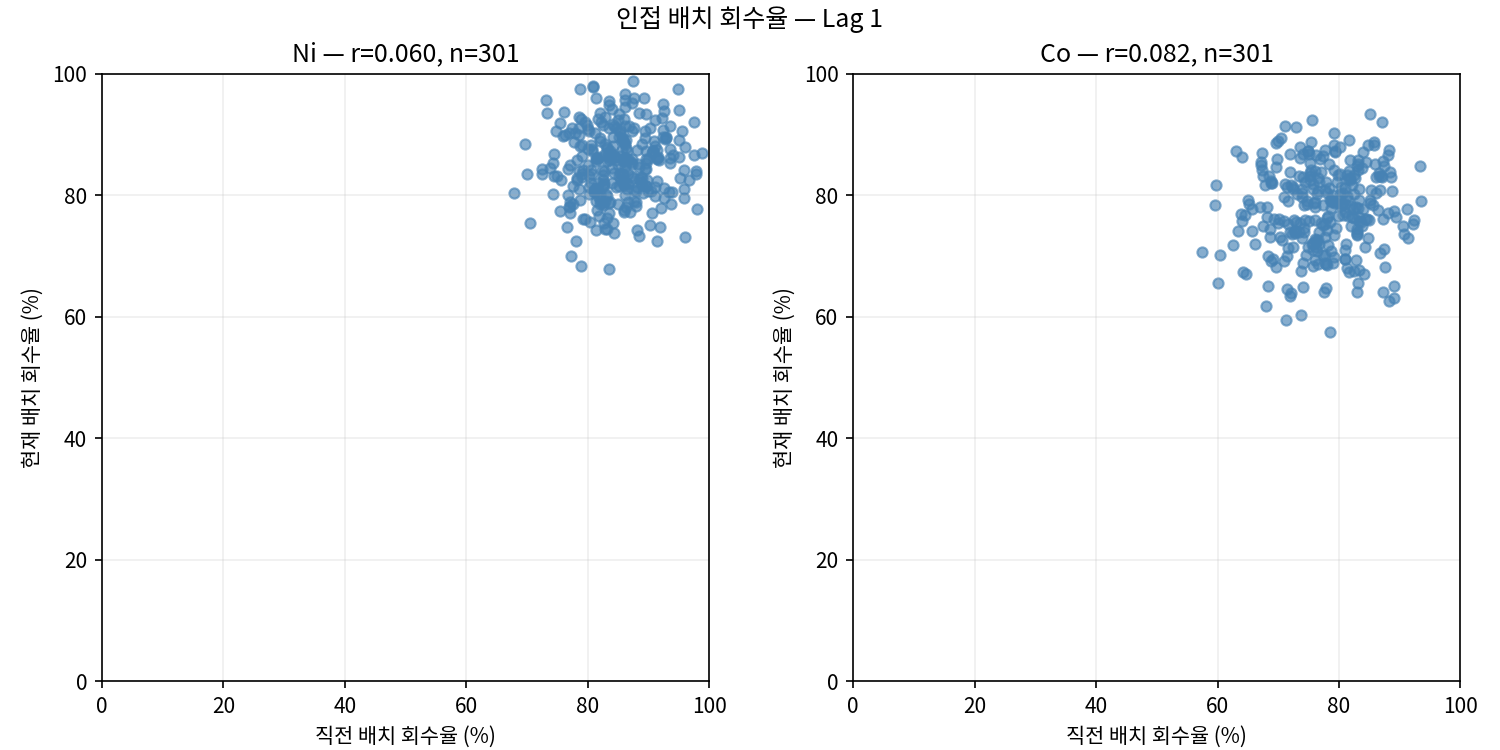

배치ID가 연속한 개발 데이터 쌍 기준


,target,pairs,lag1_correlation
0,Ni_회수율_pct,301,0.060326
1,Co_회수율_pct,301,0.082389


In [4]:
import matplotlib.pyplot as plt

lag_pool = pre_impute_df.loc[pre_impute_df['split'].isin(['train', 'validation'])].copy()
lag_pool['배치순번'] = pd.to_numeric(lag_pool['배치ID'].str.extract(r'(\d+)$')[0], errors='raise')
if lag_pool['배치순번'].duplicated().any():
    raise ValueError('중복된 배치 숫자 순번 확인 필요함')
lag_pool = lag_pool.sort_values('배치순번')
previous = lag_pool.shift(1)
adjacent = lag_pool['배치순번'].diff().eq(1)
lag_rows = []
for target in TARGET_COLUMNS:
    valid = adjacent & lag_pool[target].notna() & previous[target].notna()
    x, y = previous.loc[valid, target], lag_pool.loc[valid, target]
    lag_rows.append({'target': target, 'pairs': len(x), 'lag1_correlation': x.corr(y)})
lag_summary = pd.DataFrame(lag_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
for ax, target, metal in zip(axes, TARGET_COLUMNS, ['Ni', 'Co']):
    valid = adjacent & lag_pool[target].notna() & previous[target].notna()
    x, y = previous.loc[valid, target], lag_pool.loc[valid, target]
    r = x.corr(y)
    ax.scatter(x, y, s=24, alpha=.65, color='steelblue')
    ax.set(title=f'{metal} — r={r:.3f}, n={len(x)}',
           xlabel='직전 배치 회수율 (%)', ylabel='현재 배치 회수율 (%)',
           xlim=(0, 100), ylim=(0, 100))
    ax.set_aspect('equal')
    ax.grid(alpha=.2)
fig.suptitle('인접 배치 회수율 — Lag 1')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
lag_path = FIGURES_DIR / 'lag1_recovery.png'
fig.savefig(lag_path, dpi=150)
plt.close(fig)
lag_summary.to_csv(FIGURES_DIR / 'lag1_recovery.csv', index=False)
display(Image(filename=str(lag_path)))
print('배치ID가 연속한 개발 데이터 쌍 기준')
display(lag_summary)

**현재 개발 데이터의 분석 결과**

- Ni·Co의 인접 쌍 Pearson 상관계수는 각각 0.060·0.082로 낮게 나타났으며, 이 결과는 배치 독립성을 입증하는 근거로 사용하지 않음
- 두 타깃 모두 유효 쌍 수는 301쌍이며 입력 데이터 변경 시 재확인 필요함

### 3.2 대치 전 원변수 분포

- 개발 데이터의 대치 전 관측값으로 분포의 치우침과 극단값 영향을 확인함
- 아래 히스토그램은 이상값 처리 후 남은 관측값 기준임

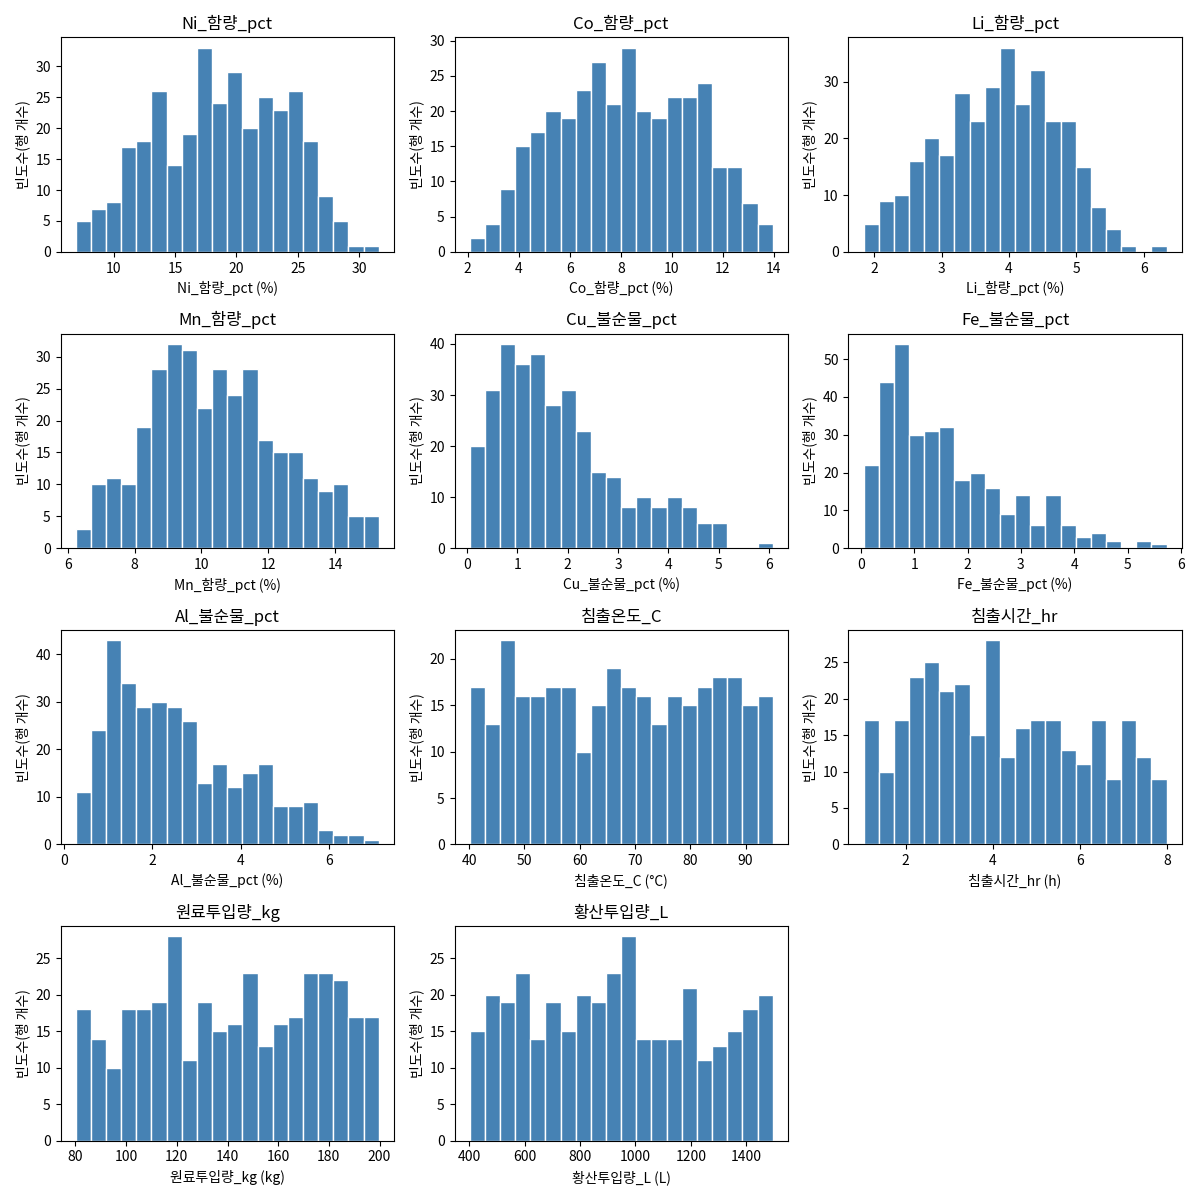

In [5]:
from module1_preprocessing.validation import plot_numeric_histograms

histogram_df = pre_impute_df.loc[pre_impute_df['split'].isin(['train', 'validation'])]
display(Image(filename=str(plot_numeric_histograms(
    histogram_df, BASE_FEATURES, FIGURES_DIR
))))

## 4. 결측치 대치

- Train에서 대치 기준을 계산하고 Validation·Test에 동일하게 적용함
- 교차검증에서는 각 fold의 학습 데이터에서 대치 기준을 다시 계산함

| 대상 | 방법 | 선정 근거 |
|---|---|---|
| 조성 7종 | Train 원료등급별 중앙값 | 등급별 성분 차이 반영 및 극단값 영향 완화 |
| 침출 온도·시간 | Train 전체 중앙값 | 배치 간 조건의 연속성을 가정하기 어려움 |
| 황산 투입량 | Train 원료 투입량 기반 선형회귀 | 원료 처리량과 황산 투입량 간 관계 반영 |

- 등급별 중앙값을 구할 수 없는 경우 Train 전체 중앙값 사용함
- 아래 그림은 이상값 처리 후부터 날짜 보간·수치형 대치 완료까지의 결측률 변화임

In [6]:
train_df = interpolated_df.loc[train_i].copy()
imputed_df = impute_missing_from_reference(train_df, interpolated_df)

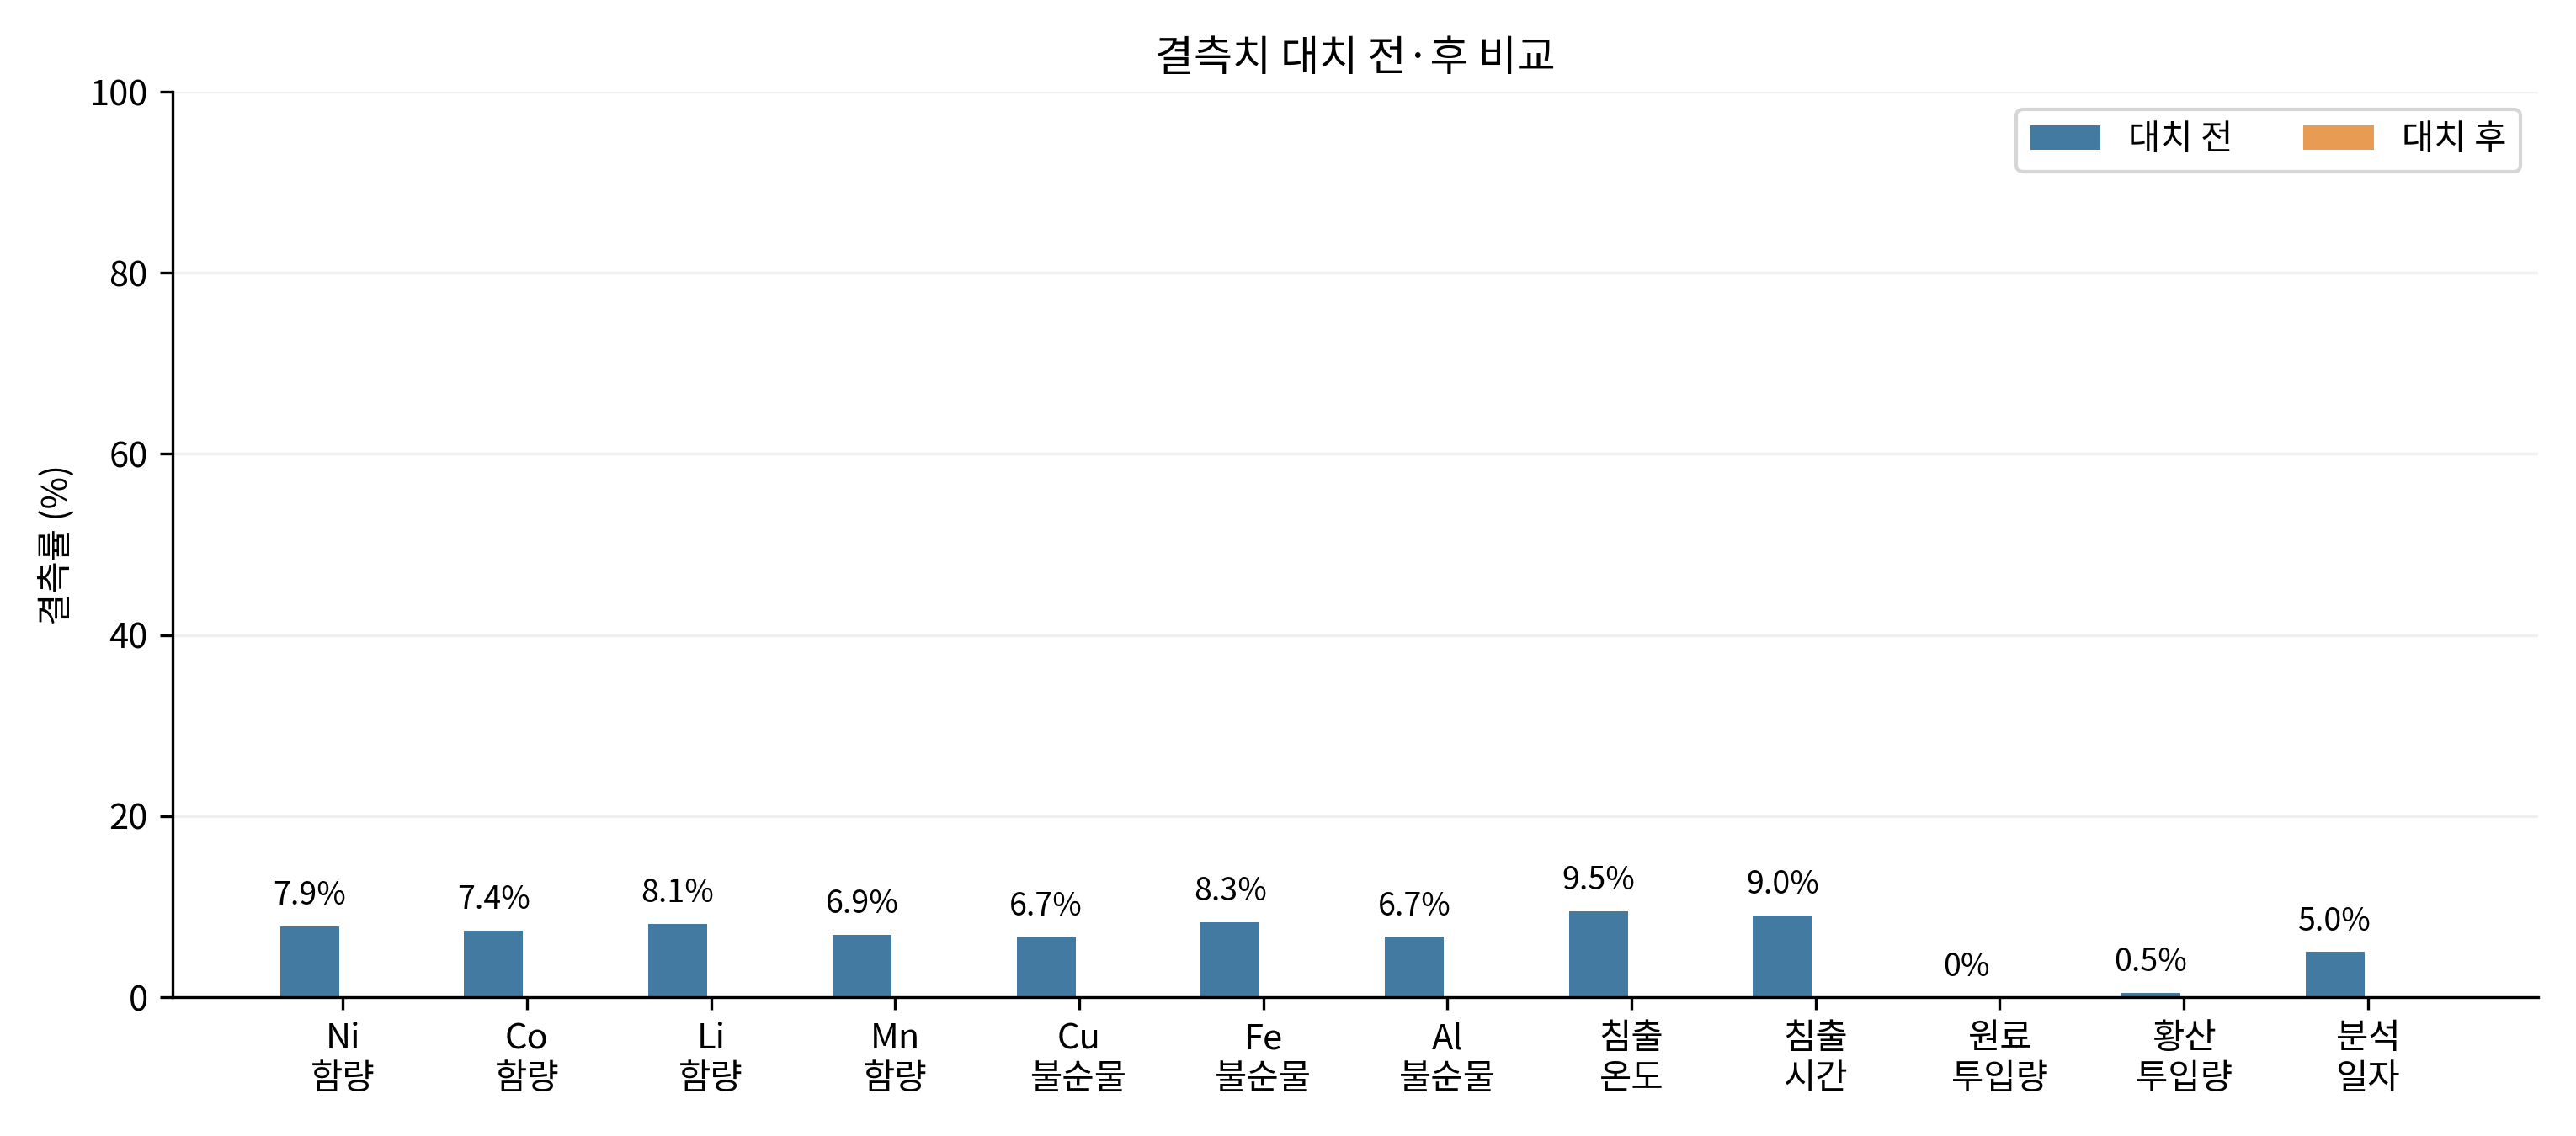

In [7]:
missing_compare_cols = COMPOSITION_COLUMNS + PROCESS_COLUMNS + [
    '원료투입량_kg', '황산투입량_L', '분석일자'
]
display(Image(filename=str(plot_missing_before_after(
    outlier_flagged_df, imputed_df, FIGURES_DIR, missing_compare_cols
))))

## 5. 특성 공학

- 원료 조성과 운전조건의 관계를 표현하는 파생변수 4종을 생성함

| 변수 | 계산식 | 의미 |
|---|---|---|
| `acid_to_ore_ratio` | 황산 투입량 ÷ 원료 투입량 | 원료 질량당 산 투입 부피 L/kg |
| `leach_intensity` | 침출 온도 × 침출 시간 | 온도·시간 결합 지표 |
| `total_impurity_pct` | Cu + Fe + Al | 측정한 세 불순물의 합계 wt% |
| `feed_impurity_g_per_l` | 10 × 불순물 합계 ÷ 산 투입비 | 산 투입 부피당 원료 내 불순물 질량 g/L |

- 파생변수의 예측 기여도는 7절의 특징 조합 비교에서 확인함

In [8]:
for col in ['원료투입량_kg', '황산투입량_L']:
    bad_batches = imputed_df.loc[imputed_df[col] <= 0, '배치ID'].tolist()
    if bad_batches:
        raise ValueError(f'{col}이 0 이하인 배치로 파생변수 계산 불가: {bad_batches}')
final_df = engineer_features(imputed_df)
final_df = final_df.join(check_composition_sum(final_df))
final_df.loc[train_i].head()

,배치ID,분석일자,원료등급,Ni_함량_pct,Co_함량_pct,Li_함량_pct,Mn_함량_pct,Cu_불순물_pct,Fe_불순물_pct,Al_불순물_pct,...,target_purity_ratio,analysis_month,Fe_Ni_ratio,Cu_Ni_ratio,Al_Ni_ratio,feed_impurity_g_per_l,acid_per_target_L_kg,acid_time,composition_sum_pct,composition_sum_review_flag
1,BP-2025-0002,2025-01-02,B,12.17,6.98,4.25,10.49,1.90,2.040,3.43,...,0.722097,1,0.167625,0.156122,0.281841,10.488077,36.694658,44.410811,41.260,False
2,BP-2025-0003,2025-01-03,C,11.83,6.76,3.06,10.33,2.97,1.870,3.52,...,0.689796,1,0.158073,0.251057,0.297549,10.033564,44.819980,33.328137,40.340,False
3,BP-2025-0004,2025-01-03,B,17.10,9.21,4.83,8.51,2.00,0.980,2.83,...,0.819116,1,0.057310,0.116959,0.165497,3.933230,56.144331,117.877157,45.460,False
4,BP-2025-0005,2025-01-03,A,23.67,10.68,5.06,8.09,0.64,0.595,0.94,...,0.940452,1,0.025137,0.027038,0.039713,3.252294,19.468958,23.005300,49.675,False
5,BP-2025-0006,2025-01-03,C,13.07,4.75,3.20,12.72,4.69,3.140,2.88,...,0.624606,1,0.240245,0.358837,0.220352,8.028060,74.863681,40.022124,44.450,False


## 6. 데이터 검증 및 처리 후 EDA

- 모델 입력과 회수율의 잔여 결측·무한대 및 회수율의 0–100% 범위 확인함
- 원변수가 정상범위 또는 문헌 기반 보존 범위를 충족하는지 점검함
- 동일 시료·동일 질량 기준의 조성 7종 합계가 100%를 초과하는 배치를 검토 대상으로 표시함

In [9]:
for stage, column in [('대치 전', 'pre_impute_composition_sum_review_flag'),
                      ('대치 후', 'composition_sum_review_flag')]:
    batches = final_df.loc[final_df[column].fillna(False), '배치ID'].tolist()
    print(f'{stage} 성분 합계 100% 초과 검토 대상: {batches or "없음"} — 자동 보정 없음')

model_features = BASE_FEATURES + DERIVED_FEATURES
remaining_missing = check_missing(final_df, columns=model_features + TARGET_COLUMNS)
if remaining_missing:
    raise ValueError(f'정제 후 잔여 결측 발견: {remaining_missing}')
validate_model_features(final_df, model_features)
validate_targets(final_df, TARGET_COLUMNS)

range_violations = check_ranges(final_df, reference_exception_ranges=REFERENCE_EXCEPTION_RANGES)
if range_violations:
    raise ValueError('정제 후 보존 기준 위반:\n' + format_range_violations(final_df, range_violations))
print('모델 입력·회수율·보존 기준 검증 통과함')
print('정상범위 이탈 현황 — 보존 예외 포함:')
print(format_range_violations(final_df, check_ranges(final_df)))

대치 전 성분 합계 100% 초과 검토 대상: 없음 — 자동 보정 없음
대치 후 성분 합계 100% 초과 검토 대상: 없음 — 자동 보정 없음
모델 입력·회수율·보존 기준 검증 통과함
정상범위 이탈 현황 — 보존 예외 포함:
변수명: Ni_함량_pct
────────────────────────────────────────
        배치ID   관측값
BP-2025-0117  7.47
BP-2025-0202  7.07
BP-2025-0219  7.70
BP-2025-0277 30.92
BP-2025-0281 30.33
BP-2025-0297  6.92
BP-2025-0327  7.61
BP-2025-0392 31.58

변수명: Li_함량_pct
────────────────────────────────────────
        배치ID  관측값
BP-2025-0160 1.84
BP-2025-0174 1.93
BP-2025-0271 6.04
BP-2025-0352 6.34

변수명: Cu_불순물_pct
────────────────────────────────────────
        배치ID  관측값
BP-2025-0037 0.29
BP-2025-0052 0.26
BP-2025-0074 0.24
BP-2025-0089 0.17
BP-2025-0140 0.05
BP-2025-0161 0.16
BP-2025-0175 0.10
BP-2025-0199 0.24
BP-2025-0225 0.23
BP-2025-0236 6.07
BP-2025-0282 0.07
BP-2025-0294 0.23
BP-2025-0362 0.05
BP-2025-0374 0.19

변수명: Fe_불순물_pct
────────────────────────────────────────
        배치ID  관측값
BP-2025-0033 0.12
BP-2025-0061 0.16
BP-2025-0108 0.05
BP-2025-0129 0.05
BP-2025-0153 0.05
BP-202

/tmp/ipykernel_1582360/1975911882.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  batches = final_df.loc[final_df[column].fillna(False), '배치ID'].tolist()


### 6.1 처리 후 분포 및 상관관계

- 원본 접근 없이 대치·특성 공학 이후 개발 데이터의 분포와 상관관계 확인함

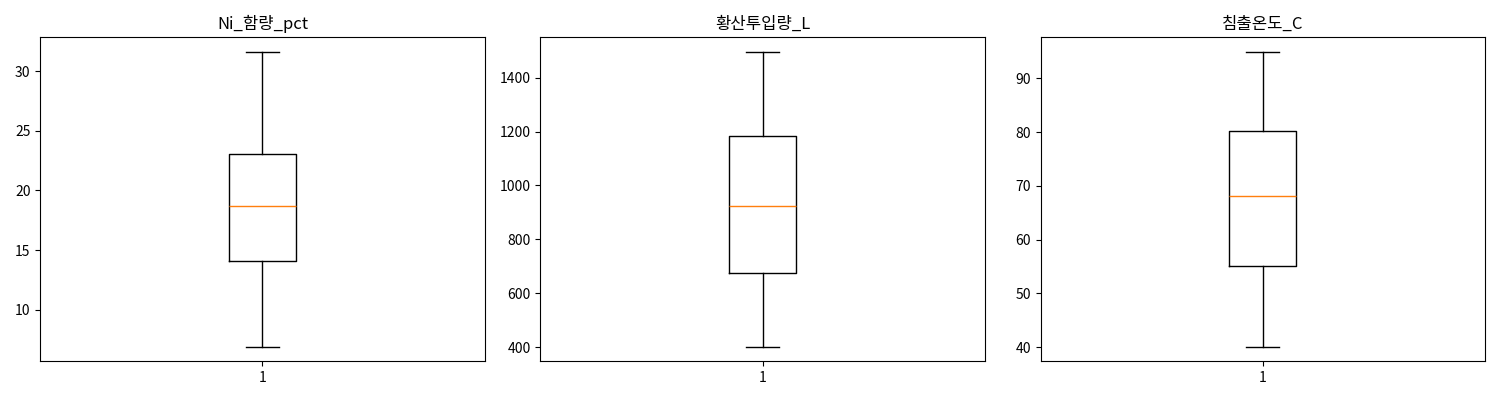

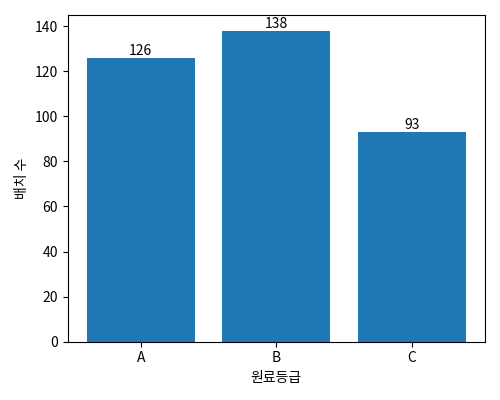

In [10]:
trainval_i = train_i.append(val_i)
for frame, folder in [(final_df.loc[trainval_i], 'after')]:
    display(Image(filename=str(plot_distributions(
        frame, ['Ni_함량_pct', '황산투입량_L', '침출온도_C'], FIGURES_DIR / folder
    ))))
display(Image(filename=str(plot_grade_distribution(final_df.loc[trainval_i], FIGURES_DIR))))

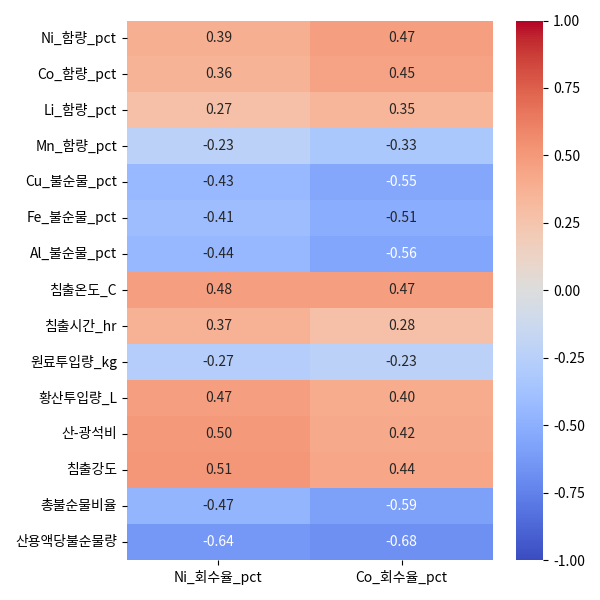

In [11]:
feature_columns = BASE_FEATURES + DERIVED_FEATURES
# 그래프에서만 한글 라벨 사용함
derived_display_labels = {
    'acid_to_ore_ratio': '산-광석비',
    'leach_intensity': '침출강도',
    'total_impurity_pct': '총불순물비율',
    'feed_impurity_g_per_l': '산용액당불순물량',
    'acid_per_target_L_kg': '목표금속당산용액량',
    'acid_time': '산투입비시간곱',
    'target_purity_ratio': '목표금속순도비',
    'Fe_Ni_ratio': 'Fe/Ni비',
    'Cu_Ni_ratio': 'Cu/Ni비',
    'Al_Ni_ratio': 'Al/Ni비',
}
trainval_i = train_i.append(val_i)
display(Image(filename=str(plot_correlation_heatmap(
    final_df.loc[trainval_i], feature_columns, TARGET_COLUMNS, FIGURES_DIR,
    display_labels=derived_display_labels,
))))

**해석 기준**

- 상관관계는 연관성 탐색용이며 인과관계나 예측 기여도를 뜻하지 않음
- 예측 기여도는 동일한 CV 조건의 ablation test로 별도 확인함

### 6.2 월별 변화 탐색 및 날짜·월의 사용 범위

- 대치 전 개발 데이터에서 실제 분석일자가 있는 배치만 사용함
- 월별 회수율·원료등급 구성비·입력변수의 평균 변화를 확인함
- 입력변수는 단위를 맞춰 비교하도록 z-score로 표시함
- 분석일자·월은 변화 탐색에 활용하며, 반복되는 계절 효과가 확인되지 않은 현재 모델에서는 입력으로 사용하지 않음

개발 데이터 357행 중 실제 분석일자 확인 340행 사용함
분석일자 결측 17행 제외함 — 보간 날짜 미사용


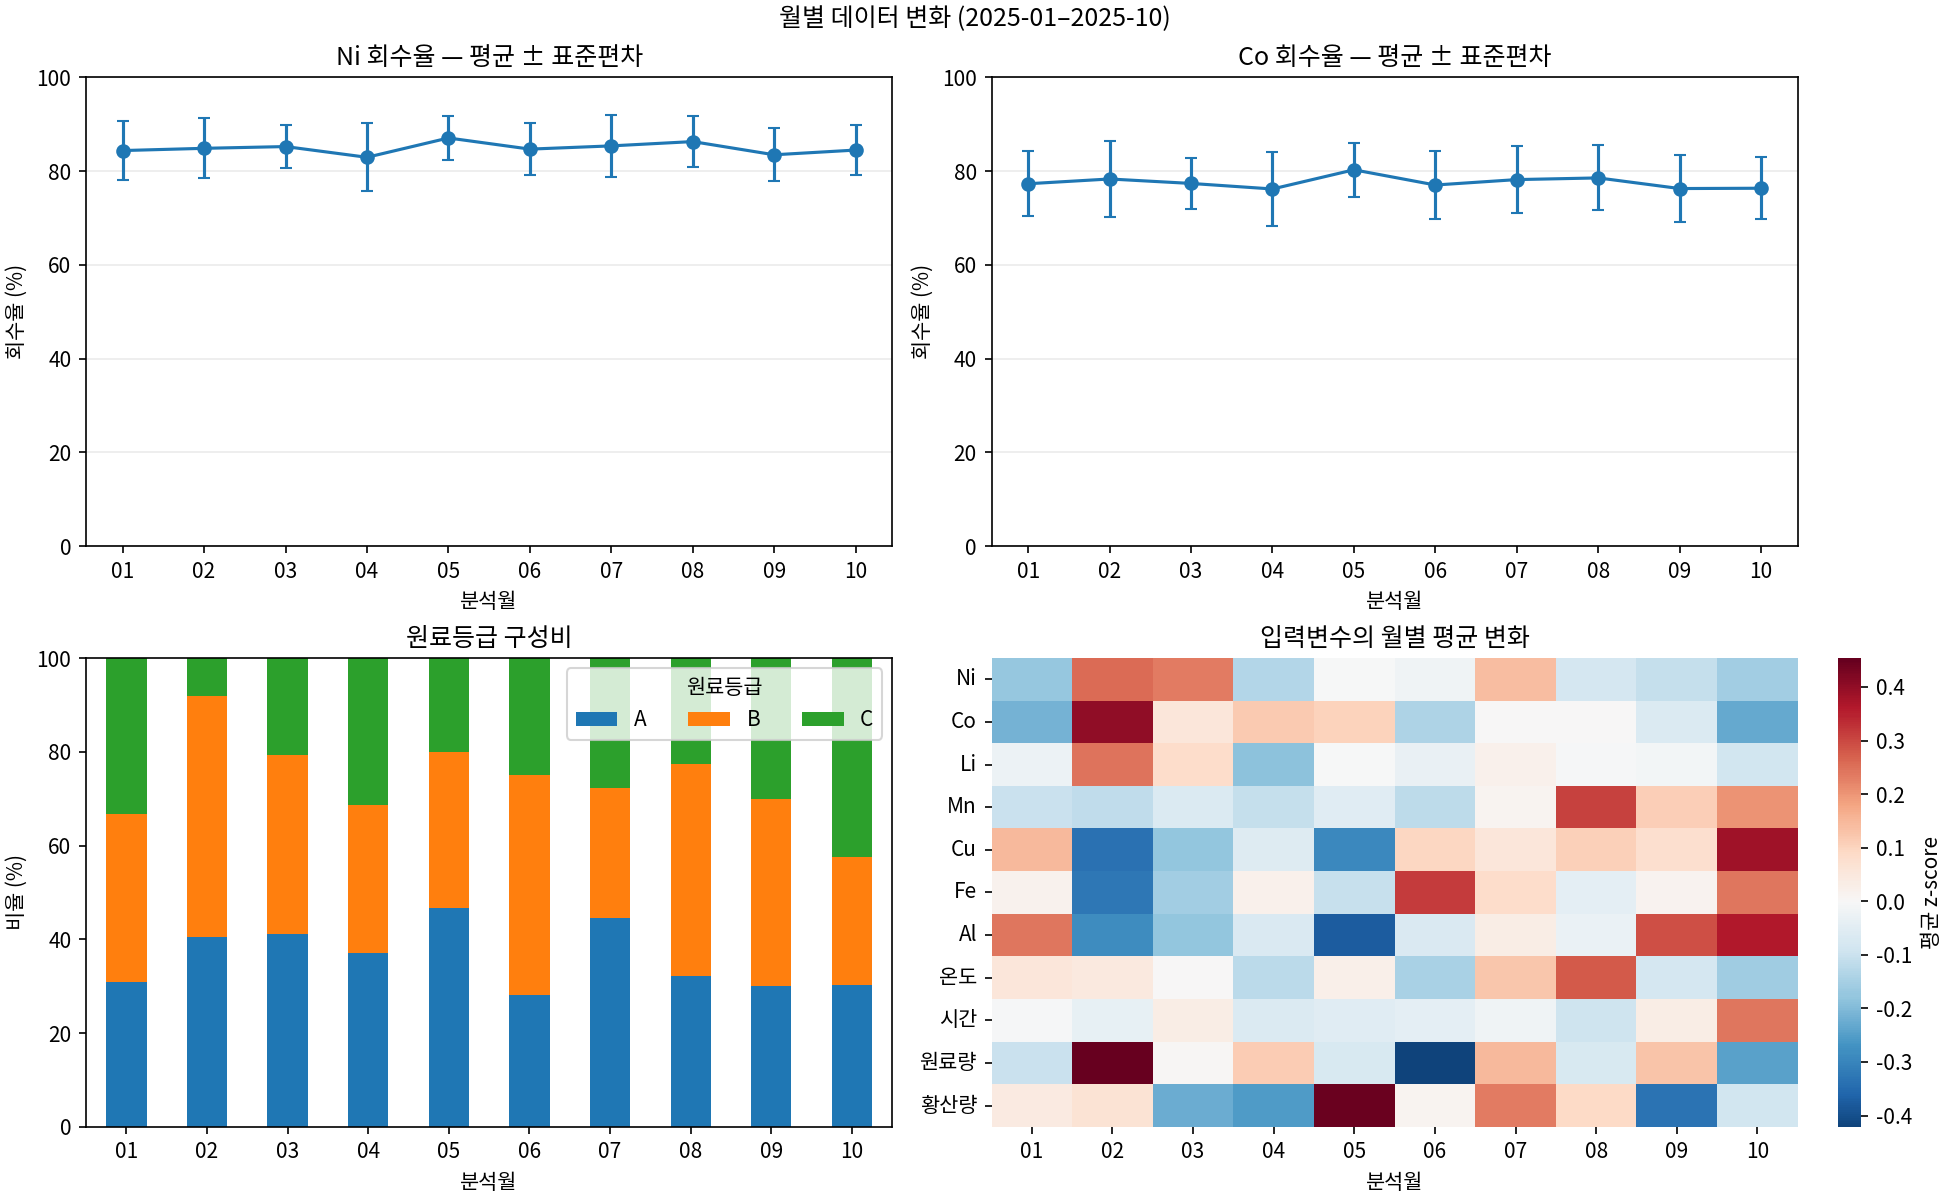

Ni_회수율_pct              Co_회수율_pct             
             count   mean   std      count   mean   std
분석월                                                    
2025-01         42  84.36  6.34         42  77.29  6.92
2025-02         37  84.84  6.38         37  78.30  8.02
2025-03         34  85.22  4.60         34  77.35  5.52
2025-04         35  82.93  7.25         35  76.17  7.92
2025-05         30  87.05  4.75         30  80.26  5.73
2025-06         32  84.67  5.53         32  77.02  7.29
2025-07         36  85.36  6.67         36  78.17  7.19
2025-08         31  86.28  5.43         31  78.53  6.93
2025-09         30  83.46  5.61         30  76.26  7.10
2025-10         33  84.47  5.43         33  76.33  6.62

Ni_회수율_pct: 월평균 82.93–87.05%, 최대 차이 4.12%p
Co_회수율_pct: 월평균 76.17–80.26%, 최대 차이 4.09%p
월별 평균 차이는 탐색 결과이며 드리프트 유무·배치 독립성의 확정 근거는 아님


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

monthly_pool = pre_impute_df.loc[pre_impute_df['split'].isin(['train', 'validation'])].copy()
observed_dates = pd.to_datetime(monthly_pool['분석일자'], errors='coerce')
print(f'개발 데이터 {len(monthly_pool)}행 중 실제 분석일자 확인 {observed_dates.notna().sum()}행 사용함')
print(f'분석일자 결측 {observed_dates.isna().sum()}행 제외함 — 보간 날짜 미사용')
monthly_pool = monthly_pool.loc[observed_dates.notna()].copy()
monthly_pool['분석월'] = observed_dates.loc[monthly_pool.index].dt.to_period('M').astype(str)
if monthly_pool.empty:
    print('월별 분석에 사용할 관측 날짜 없음')
else:
    months = sorted(monthly_pool['분석월'].unique())
    monthly_summary = monthly_pool.groupby('분석월')[TARGET_COLUMNS].agg(['count', 'mean', 'std'])
    grade_ratio = pd.crosstab(monthly_pool['분석월'], monthly_pool['원료등급'], normalize='index').reindex(months) * 100
    observed_inputs = monthly_pool[BASE_FEATURES]
    scales = observed_inputs.std().replace(0, float('nan'))
    input_z = (observed_inputs - observed_inputs.mean()) / scales
    monthly_z = input_z.groupby(monthly_pool['분석월']).mean().reindex(months)
    labels = {'Ni_함량_pct': 'Ni', 'Co_함량_pct': 'Co', 'Li_함량_pct': 'Li', 'Mn_함량_pct': 'Mn',
              'Cu_불순물_pct': 'Cu', 'Fe_불순물_pct': 'Fe', 'Al_불순물_pct': 'Al',
              '침출온도_C': '온도', '침출시간_hr': '시간', '원료투입량_kg': '원료량', '황산투입량_L': '황산량'}
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
    for ax, target, metal in zip(axes[0], TARGET_COLUMNS, ['Ni', 'Co']):
        stats = monthly_summary[target].reindex(months)
        x = range(len(months))
        ax.errorbar(x, stats['mean'], yerr=stats['std'], marker='o', capsize=3)
        ax.set_xticks(list(x), [m[5:] for m in months])
        ax.set(title=f'{metal} 회수율 — 평균 ± 표준편차', xlabel='분석월', ylabel='회수율 (%)', ylim=(0, 100))
        ax.grid(axis='y', alpha=.25)
    grade_ratio.plot.bar(stacked=True, ax=axes[1, 0], rot=0)
    axes[1, 0].set_xticklabels([m[5:] for m in months])
    axes[1, 0].set(title='원료등급 구성비', xlabel='분석월', ylabel='비율 (%)', ylim=(0, 100))
    axes[1, 0].legend(title='원료등급', ncols=3)
    sns.heatmap(monthly_z.rename(columns=labels).T, ax=axes[1, 1], cmap='RdBu_r', center=0,
                xticklabels=[m[5:] for m in months], cbar_kws={'label': '평균 z-score'})
    axes[1, 1].set(title='입력변수의 월별 평균 변화', xlabel='분석월', ylabel='')
    fig.suptitle(f'월별 데이터 변화 ({months[0]}–{months[-1]})')
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    monthly_path = FIGURES_DIR / 'monthly_changes.png'
    fig.savefig(monthly_path, dpi=150)
    plt.close(fig)
    monthly_summary.to_csv(FIGURES_DIR / 'monthly_summary.csv')
    grade_ratio.to_csv(FIGURES_DIR / 'monthly_grade_ratio.csv')
    monthly_z.to_csv(FIGURES_DIR / 'monthly_input_zscore.csv')
    display(Image(filename=str(monthly_path)))
    display(monthly_summary.round(2))
    for target in TARGET_COLUMNS:
        means = monthly_summary[target]['mean'].dropna()
        if len(means):
            print(f'{target}: 월평균 {means.min():.2f}–{means.max():.2f}%, 최대 차이 {means.max() - means.min():.2f}%p')
    print('월별 평균 차이는 탐색 결과이며 드리프트 유무·배치 독립성의 확정 근거는 아님')

**현재 개발 데이터의 월별 분석 결과**

- 분석일자가 있는 340행 사용했으며 결측 17행 제외함
- Ni 월평균은 82.93–87.05%, Co 월평균은 76.17–80.26%로 나타남
- 월평균의 최대 차이는 Ni 4.12%p, Co 4.09%p이며 원료등급 구성과 입력조건도 월별로 달랐음
- 회수율이 일정하게 증가하거나 감소하는 패턴은 뚜렷하지 않지만 월별 차이가 없다고 단정할 수 없음
- 원료·운전조건의 영향을 분리하지 않은 탐색 결과이므로 월 변수를 추가해야 한다는 근거로 바로 사용하지 않음
- 위 수치는 현재 저장된 개발 데이터 기준이며 입력 변경 시 재확인 필요함

## 7. 특징 조합 비교 및 공통 구성 채택

- 대치 전 개발 데이터에서 원료등급 기준 5-fold CV 수행함
- 각 fold의 학습 데이터에서만 대치·등급 인코딩 기준을 계산함
- 같은 LightGBM·분할 조건에서 네 조합을 비교함

| 조합 | 입력 |
|---|---|
| 원변수 | 11종 |
| 원변수 + 파생변수 | 11종 + 파생 4종 |
| 원변수 + 원료등급 | 11종 + 등급 |
| 원변수 + 파생변수 + 원료등급 | 11종 + 파생 4종 + 등급 |

- 현재 실행은 네 조합의 재평가이며 최저 오차 조합을 자동 채택하지 않음
- 기존 비교에서 승인한 원변수 11종 + 파생 4종을 Ni·Co 공통 구성으로 유지함
- 최종 모델의 종류·튜닝·평가는 Module 2에서 다룸

파생변수 전/후 성능 비교 (5-Fold CV 평균 R²·MSE·RMSE·MAE):
  base / Ni_회수율_pct: {'cv_r2': 0.8115555402008742, 'cv_mse': 6.464433941514786, 'cv_rmse': 2.5425251112849967, 'cv_mae': 1.9571828510675704, 'cv_fold_rmse_mean': 2.5403673231523145, 'cv_rmse_std': 0.11708866818959157, 'cv_mae_std': 0.08467962466975353}
  base / Co_회수율_pct: {'cv_r2': 0.7951179330860084, 'cv_mse': 9.896980145105328, 'cv_rmse': 3.1459466214647267, 'cv_mae': 2.408045126107467, 'cv_fold_rmse_mean': 3.129560070883287, 'cv_rmse_std': 0.35852808090567445, 'cv_mae_std': 0.23595918052517204}
  base_plus_grade / Ni_회수율_pct: {'cv_r2': 0.815535356561886, 'cv_mse': 6.32887223403632, 'cv_rmse': 2.5157249917342557, 'cv_mae': 1.9290186466354555, 'cv_fold_rmse_mean': 2.5130843229449344, 'cv_rmse_std': 0.12883817274356296, 'cv_mae_std': 0.051659859288723124}
  base_plus_grade / Co_회수율_pct: {'cv_r2': 0.7976772357376671, 'cv_mse': 9.76623232205711, 'cv_rmse': 3.1250971700184156, 'cv_mae': 2.418103439982572, 'cv_fold_rmse_mean': 3.1091741469989

cv_r2    cv_mse   cv_rmse    cv_mae  \
base              Ni_회수율_pct  0.811556  6.464434  2.542525  1.957183   
                  Co_회수율_pct  0.795118  9.896980  3.145947  2.408045   
base_plus_grade   Ni_회수율_pct  0.815535  6.328872  2.515725  1.929019   
                  Co_회수율_pct  0.797677  9.766232  3.125097  2.418103   
base_plus_derived Ni_회수율_pct  0.821548  6.107032  2.471241  1.940137   
                  Co_회수율_pct  0.816762  8.925252  2.987516  2.291160   
all_features      Ni_회수율_pct  0.824232  6.014703  2.452489  1.938112   
                  Co_회수율_pct  0.815885  8.963563  2.993921  2.289680   

                              cv_fold_rmse_mean  cv_rmse_std  cv_mae_std  
base              Ni_회수율_pct           2.540367     0.117089    0.084680  
                  Co_회수율_pct           3.129560     0.358528    0.235959  
base_plus_grade   Ni_회수율_pct           2.513084     0.128838    0.051660  
                  Co_회수율_pct           3.109174     0.352258    0.225882  
base_plus_derived Ni_회수율_pct           2.469072     0.115742    0.128156  
                  Co_회수율_pct           2.954847     0.492607    0.346475  
all_features      Ni_회수율_pct           2.450861     0.099903    0.114108  
                  Co_회수율_pct           2.961011     0.494942    0.353192

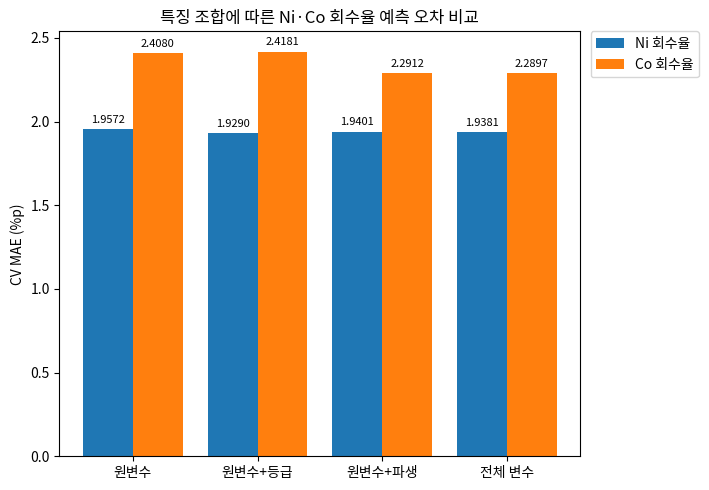

In [13]:
from module1_preprocessing.pipeline import evaluate_feature_selection

selection, lgbm_results = evaluate_feature_selection(pre_impute_df)
display(pd.DataFrame(lgbm_results).T)
display(Image(filename=str(plot_ablation_results(lgbm_results, FIGURES_DIR))))

**결과 해석**

- MAE·RMSE 단위는 %p이며 낮을수록 우수함
- 반복 비교 결과와 입력 구성의 단순성을 고려한 기존 공통 15종을 유지함 현재 CV는 재평가 결과임
- [기존 특징 비교](../module1_preprocessing/reports/derived_subset_selection/subset_summary.csv) · [SVR 추가 비교](../module2_prediction/reports/svr_feature_comparison/nested_summary.csv)
- Test의 과거 사용 이력은 최종 성능 해석 시 고려해야 함

## 8. 산출물 저장 및 Module 2 연결

- CV 결과를 재사용하여 승인된 공통 입력 15종과 평가 결과 저장함
- 대치 전 데이터·분할 정보·입력 해시를 함께 저장하여 Module 2에서 학습 구간별 대치 가능하도록 함
- 대치·파생변수 생성 결과는 품질 확인용으로 별도 저장함

In [14]:
from module1_preprocessing.pipeline import save_feature_selection

output_path = ROOT / 'module1_preprocessing/reports/processed_replay/cleaned_features.csv'
selection = save_feature_selection(pre_impute_df, selection, output_path)
final_df.to_csv(output_path, index=False)
quality_df = final_df
pd.DataFrame(selection['targets']).T

모델링 입력: /home/llsowy/Downloads/capstone/module1_preprocessing/reports/processed_replay/pre_impute_data.csv; 선택 결과: /home/llsowy/Downloads/capstone/module1_preprocessing/reports/processed_replay/feature_selection.json (Test 평가 없음)


,case,features,cv_metrics
Ni_회수율_pct,base_plus_derived,"[Ni_함량_pct, Co_함량_pct, Li_함량_pct, Mn_함량_pct, C...","{'cv_r2': 0.8215483135892601, 'cv_mse': 6.1070..."
Co_회수율_pct,base_plus_derived,"[Ni_함량_pct, Co_함량_pct, Li_함량_pct, Mn_함량_pct, C...","{'cv_r2': 0.8167620546483269, 'cv_mse': 8.9252..."


**산출물 확인**

- Ni·Co 공통 입력 15종 저장 확인함 최종 모델 평가는 Module 2에서 수행함

## 문헌 기반 보존 범위 출처

| 변수 | 정상범위 밖 보존 경계 wt% | 근거 |
|---|---|---|
| Ni | 하한 5.9 / 상한 38.2 | [Table 3 NMC](https://doi.org/10.1016/j.ceramint.2024.08.220) / [Table 2](https://doi.org/10.1021/acssuschemeng.5c10344) |
| Li | 하한 1.81 / 상한 6.76 | [OREAS AC18.10665](https://www.oreas.com/crm/ac18-10665/) / [Table 1](https://doi.org/10.7844/kirr.2024.33.1.58) |
| Cu | 하한 0.05 / 상한 6.08 | [Table A1](https://publications.rwth-aachen.de/record/1024070/files/1024070.pdf) / [Table 1](https://doi.org/10.7844/kirr.2024.33.1.58) |
| Fe | 하한 0.02 | [§3.1](https://doi.org/10.1016/j.wasman.2025.115136) |
| Al | 하한 0.13 / 상한 7.46 | [Table 1](https://doi.org/10.1016/j.ceja.2024.100648) / [OREAS AC18.10664](https://www.oreas.com/crm/ac18-10664/) |

- Co·Mn은 예외 없음 [Mn 15.95 wt% 사례](https://doi.org/10.1039/D4SU00427B)는 정상범위 안이므로 상한 확대에 미사용함
- 문헌 보고값과 정상범위를 연결한 프로젝트 보존 기준이며 보편적인 정상범위는 아님
- 원료 종류·보고값·서지정보는 [문헌 근거 정리](../docs/reference_ranges.md)에 기재함